# Tonight's Dulles freeze probability and the pretreatment decision
**Question:** At 4 p.m. Eastern, can a forecast improve overnight pretreatment decisions compared with waiting to see ice?

**Measurement:** minimum of the hourly Dulles air-temperature readings from **6 p.m. on the decision date through 8 a.m. the following morning**, in °F. This fixes the earlier calendar-day/overnight mismatch. It remains an hourly-sampled airport-air measurement, not continuous pavement temperature or observed lot ice.

**Decision target:** probability of a campus-lot freeze, represented here by an explicit airport-temperature proxy. Follow professor issue #1's requested convention: proxy freeze when $T_{night}\le32-m$°F, with assumed margins **m = 2, 4, 6°F**, giving cutoffs **30, 28, 26°F**. The margins are sensitivity assumptions, not measured offsets or calibrated lot-freeze probabilities. No single margin is selected from test performance. In particular, 'pavement colder' alone does not establish the direction or size of a Dulles-to-campus correction; paired local readings are needed to check the professor's below-32 convention.

Primary baseline: **wait to see ice**, which misses that night's freeze before reactive treatment. Persistence is an additional forecast comparison. Source feedback: https://github.com/mrahma32/aii600-final-project/issues/1 . This revision supersedes the earlier daily-air/32°F scoring; the earlier scores are not directly comparable.

AI disclosure: ChatGPT/Codex prepared the analysis and draft explanations. Team members must review and understand the assumptions before merging.


In [1]:
from pathlib import Path
import gzip
import hashlib
import io
import json
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.linear_model import LinearRegression
from IPython.display import display, Markdown

ROOT = Path.cwd()
FIG = ROOT / 'fig'
FIG.mkdir(exist_ok=True)
MARGINS = [2, 4, 6]
RATIOS = [2, 5, 10]
SEED = 600
rng = np.random.default_rng(SEED)
plt.rcParams.update({'figure.figsize': (10,4), 'axes.spines.top': False, 'axes.spines.right': False})
def save(name):
    plt.tight_layout()
    plt.savefig(FIG/name, dpi=150, bbox_inches='tight')
    plt.show()


## Data provenance and a defined overnight window
NOAA ISD-Lite, station **724030-93738**, verified against the bundled NOAA station history as **WASHINGTON DULLES INTERNATIONAL AP / KIAD**, latitude 38.935, longitude −77.447, elevation 89.5 m.

Official archive: https://noaa-isd-pds.s3.amazonaws.com/isd-lite/data/ . Format and technical documents are included in the snapshot and linked in `data/README.md`. NOAA rounded near-top-of-hour observations and resolved duplicates using a ranking system. The Lite format omits individual quality flags and adds no extra quality control; we cannot claim every reading passed a quality check. Reject missing −9999 values; do not impute temperatures.

Read UTC observations, convert to **America/New_York** with daylight-saving transitions, and assign early-morning readings to the previous evening's decision date. Require every expected hourly slot in the overnight window, including the 14/16-slot DST nights (normally 15). This reduces missing-target bias, but complete-case selection may still bias the sample. Hourly minima can miss a colder temperature between observations.

Use decision dates 2000–2024. The legacy ISD archive ends during 2025, so a complete 2025 test year is unavailable. The 2025 file supplies the morning after 31 December 2024; later 2025 observations are not analyzed. This cutoff change follows source availability, not model performance. The old GHCN daily snapshot stays on the release for history but is not read by this revision.


,USAF,WBAN,STATION NAME,CTRY,STATE,ICAO,LAT,LON,ELEV(M),BEGIN,END
19312,724030,93738,WASHINGTON DULLES INTERNATIONAL AP,US,VA,KIAD,+38.935,-077.447,+0089.5,19730101,20250827


Hourly source records: 224836
Candidate nights: 9132 ; complete nights: 9077 ; excluded incomplete nights: 55


,candidate_nights
expected_hours,
14,25
15,9082
16,25


,tmin_f
count,9077.00
mean,47.97
std,16.83
min,-0.94
25%,33.98
50%,48.92
75%,62.96
max,80.06


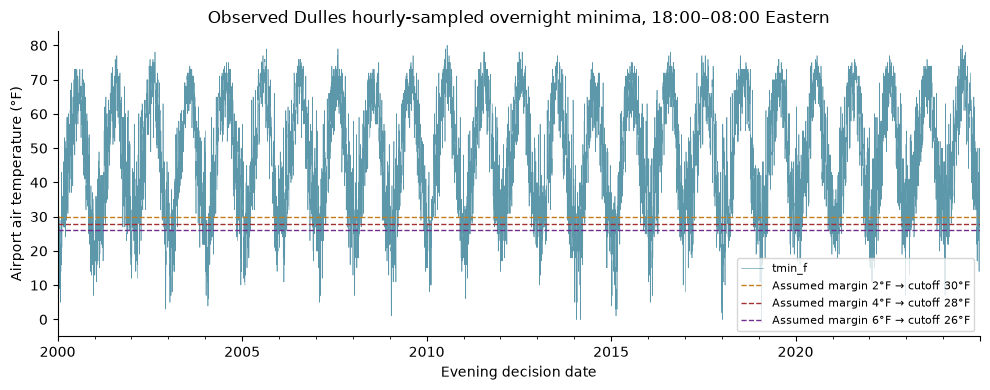

In [2]:
manifest = json.loads((ROOT/'hourly_manifest.json').read_text())
archive = ROOT/'data'/manifest['archive']
assert manifest['sha256'] == 'eae3997bb1d911aed49bdb0c974aaac8d0aa389695f0e2483b4ea2cee827ee74'
assert hashlib.sha256(archive.read_bytes()).hexdigest() == manifest['sha256'], 'Wrong hourly snapshot'
frames=[]
with zipfile.ZipFile(archive) as z:
    assert set(z.namelist()) == set(manifest['files'])
    for name, info in manifest['files'].items():
        data = z.read(name)
        assert hashlib.sha256(data).hexdigest() == info['sha256'], name
        if name.endswith('.gz'):
            part = pd.read_csv(io.BytesIO(gzip.decompress(data)), sep=r'\s+', header=None,
                               usecols=[0,1,2,3,4], names=['year','month','day','hour','temp_tenths_c'])
            frames.append(part)
    history = pd.read_csv(io.BytesIO(z.read('isd-history.csv')), dtype=str)
station = history[(history.USAF == '724030') & (history.WBAN == '93738')]
assert len(station) == 1 and station.iloc[0].ICAO == 'KIAD'
display(station)
raw = pd.concat(frames, ignore_index=True)
times = pd.to_datetime(raw[['year','month','day','hour']], utc=True)
assert not times.duplicated().any(), 'Duplicate source timestamps need review'
values = raw.temp_tenths_c.where(raw.temp_tenths_c != -9999) / 10 * 9/5 + 32
hourly = pd.Series(values.to_numpy(), index=pd.DatetimeIndex(times), name='air_f').sort_index()
# Construct the expected grid independently of observed records; preserve missing slots.
grid = pd.date_range('2000-01-01', '2025-01-02', freq='h', tz='UTC').tz_convert('America/New_York')
h = hourly.reindex(grid).to_frame()
local = h.index.tz_localize(None)
h['night_date'] = local.normalize() - pd.to_timedelta((local.hour <= 8).astype(int), unit='D')
h = h[(h.index.hour >= 18) | (h.index.hour <= 8)]
night = h.groupby('night_date').agg(tmin_f=('air_f','min'), observed_hours=('air_f','count'), expected_hours=('air_f','size'))
night = night.reindex(pd.date_range('2000-01-01','2024-12-31',name='night_date'))
night.loc[night.observed_hours != night.expected_hours, 'tmin_f'] = np.nan
print('Hourly source records:', len(raw))
print('Candidate nights:', len(night), '; complete nights:', night.tmin_f.notna().sum(), '; excluded incomplete nights:', night.tmin_f.isna().sum())
display(night.expected_hours.value_counts().sort_index().rename('candidate_nights').to_frame())
display(night[['tmin_f']].describe().round(2))
ax=night.tmin_f.plot(lw=.45, alpha=.7, color='#176b87')
for margin, color in zip(MARGINS, ['#c47d18','#a33030','#702e8c']):
    ax.axhline(32-margin, ls='--', lw=1, color=color, label=f'Assumed margin {margin}°F → cutoff {32-margin}°F')
ax.set(title='Observed Dulles hourly-sampled overnight minima, 18:00–08:00 Eastern', ylabel='Airport air temperature (°F)', xlabel='Evening decision date')
ax.legend(fontsize=8, ncol=1)
save('raw_temperature.png')


## Chronological split and model
Fit through **2018-12-31**. Estimate predictive uncertainty on **2019-01-01–2021-12-31** only. Evaluate once on **2022-01-01–2024-12-31**. Keep those cutoffs fixed; no model/hyperparameter/margin/cost selection uses test results. This is a revised evaluation after instructor feedback; the earlier daily-target test was already inspected and is not a prospective preregistered test.

At 16:00 on decision date $t$, the night starting at $t-1$ finished at 08:00 that morning. Predictors are the two completed earlier nights and a known seasonal calendar cycle. Calendar reindexing comes before lagging; no filled gaps. Historical final records may differ from readings available in real time; publication delays still need auditing.

Additional persistence forecast: $\hat T_t=T_{t-1}$. Regression:
$T_t=\beta_0+\beta_1T_{t-1}+\beta_2T_{t-2}+\beta_3\sin(2\pi d_t/365.2425)+\beta_4\cos(2\pi d_t/365.2425)+e_t$.
Intercept and seasonal coefficients are in °F; lag coefficients are °F/°F and describe conditional persistence. This is an interpretable association, not a causal model. More flexible models may capture fronts better but add complexity/tuning. The least-trusted assumption is that the seasonal linear relationship and calibration residual distribution transfer to future cold weather.

For each method use $T_t^*=\hat T_t+e_j^{cal}$; empirical residual quantiles yield a nominal 90% prediction interval. No normal residual assumption or guaranteed conditional coverage is claimed.


In [3]:
df=night[['tmin_f']].copy()
df['lag1']=df.tmin_f.shift(1)
df['lag2']=df.tmin_f.shift(2)
angle=2*np.pi*(df.index.day_of_year-1)/365.2425
df['sin_year'],df['cos_year']=np.sin(angle),np.cos(angle)
features=['lag1','lag2','sin_year','cos_year']
usable=df.dropna(subset=['tmin_f']+features)
train=usable.loc[:'2018-12-31'].copy()
cal=usable.loc['2019-01-01':'2021-12-31'].copy()
test=usable.loc['2022-01-01':'2024-12-31'].copy()
assert train.index.max() < cal.index.min() < test.index.min()
# The most recent predictor night ends at 08:00, eight hours before the 16:00 decision.
assert (test.index + pd.Timedelta(hours=8) < test.index + pd.Timedelta(hours=16)).all()
split_table=pd.DataFrame([{'split':name,'first_evening':str(p.index.min().date()),'last_evening':str(p.index.max().date()),'nights':len(p),
    **{f'proxy_freeze_m{m}':int((p.tmin_f<=32-m).sum()) for m in MARGINS}}
    for name,p in [('train',train),('calibration',cal),('test',test)]])
display(split_table)
print('Excluded target/predictor rows:', len(df)-len(usable))
model=LinearRegression().fit(train[features],train.tmin_f)
display(pd.Series([model.intercept_,*model.coef_],index=['intercept']+features,name='coefficient').round(4).to_frame())
pred_cal={'Persistence':cal.lag1.to_numpy(),'Forecast rule':model.predict(cal[features])}
pred_test={'Persistence':test.lag1.to_numpy(),'Forecast rule':model.predict(test[features])}
errors_cal={name:cal.tmin_f.to_numpy()-p for name,p in pred_cal.items()}
actual=test.tmin_f.to_numpy()
intervals={}
forecast_rows=[]
prob={}
for name,pred in pred_test.items():
    err=errors_cal[name]
    lo,hi=np.quantile(err,[.05,.95])
    intervals[name]=(pred+lo,pred+hi)
    forecast_rows.append({'method':name,'MAE_F':abs(actual-pred).mean(),'RMSE_F':np.sqrt(np.mean((actual-pred)**2)),
        'mean_error_F':(actual-pred).mean(),'90pct_interval_coverage':((actual>=pred+lo)&(actual<=pred+hi)).mean(),'interval_width_F':hi-lo})
    for margin in MARGINS:
        prob[name,margin]=(pred[:,None]+err[None,:] <= 32-margin).mean(axis=1)
forecast_scores=pd.DataFrame(forecast_rows)
display(forecast_scores.round(4))
forecast_scores.to_csv(FIG/'forecast_scores.csv',index=False)
split_table.to_csv(FIG/'split_summary.csv',index=False)


,split,first_evening,last_evening,nights,proxy_freeze_m2,proxy_freeze_m4,proxy_freeze_m6
0,train,2000-01-03,2018-12-31,6795,1170,923,739
1,calibration,2019-01-01,2021-12-31,1096,153,110,76
2,test,2022-01-01,2024-12-31,1093,149,104,81


Excluded target/predictor rows: 148


,coefficient
intercept,23.2206
lag1,0.6000
lag2,-0.0879
sin_year,-3.0437
cos_year,-9.6524


,method,MAE_F,RMSE_F,mean_error_F,90pct_interval_coverage,interval_width_F
0,Persistence,6.4639,8.3852,-0.0155,0.8902,26.8200
1,Forecast rule,5.7436,7.3302,0.7214,0.8811,22.3464


## Explicit action and the required waiting-for-ice baseline
For margin $m$, proxy freeze indicator $z_t=1(T_{night,t}\le32-m)$ and prediction $p_t(m)=P(T_{night,t}\le32-m\mid\text{available earlier observations})$. This is the **assumed measurement mapping** to lot freeze, not a validated probability of campus ice.

Let $C_w=1$ penalty unit for salting unnecessarily and $C_m=r$ for missing a proxy-freeze night. Compare all **r=2,5,10** scenarios, without inventing GMU dollars. Loss:
$L(a,z)=C_m1(a=0,z=1)+C_w1(a=1,z=0)$.
Expected losses are $C_w(1-p)$ for dispatching and $C_mp$ for standing down. **Send trucks if $p>C_w/(C_m+C_w)=1/(r+1)$**, otherwise stand down. Thresholds are **33.33%, 16.67%, 9.09%**. At exact equality either action has equal expected loss; we stand down to match the professor's strict 'exceeds' wording.

**Wait to see ice:** no preventive dispatch at the afternoon decision; if the proxy night freezes, it is missed before reactive treatment. Under the professor's stylized rule: missed nights = all proxy-freeze nights, unnecessary preventive-salting nights = 0. This is **not** an observed GMU behavior dataset, does not imply the crew never reacts, and does not measure the consequences of delayed response. All methods use the same held-out nights and the same proxy definition/costs. Persistence remains an additional benchmark; always salt is a reference.

Primary outputs report **nights missed and nights salted for nothing**, plus the weighted penalty. Correct decisions have zero regret here; complete budgets, wetness, treatment effectiveness and environmental costs are omitted. The illustrative proxy/cost sensitivity is not a final operational recommendation.


,margin_F,Dulles_cutoff_F,Cm_over_Cw,method,missed_nights,salted_for_nothing_nights,total_penalty_units
0,2,30,2,Wait to see ice,149,0,298
1,2,30,2,Forecast rule,38,83,159
4,2,30,5,Wait to see ice,149,0,745
5,2,30,5,Forecast rule,16,162,242
8,2,30,10,Wait to see ice,149,0,1490
9,2,30,10,Forecast rule,5,218,268
12,4,28,2,Wait to see ice,104,0,208
13,4,28,2,Forecast rule,40,75,155
16,4,28,5,Wait to see ice,104,0,520
17,4,28,5,Forecast rule,10,153,203


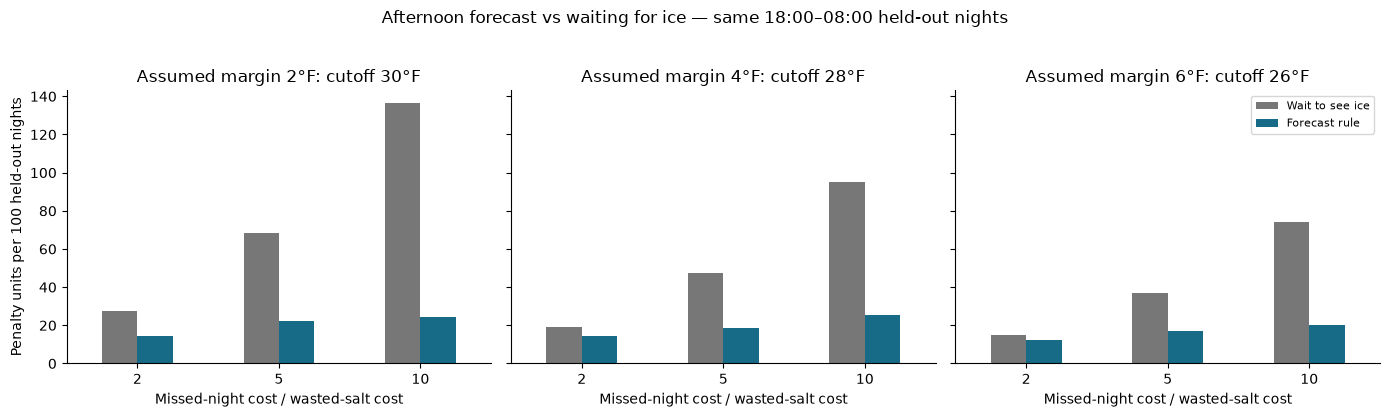

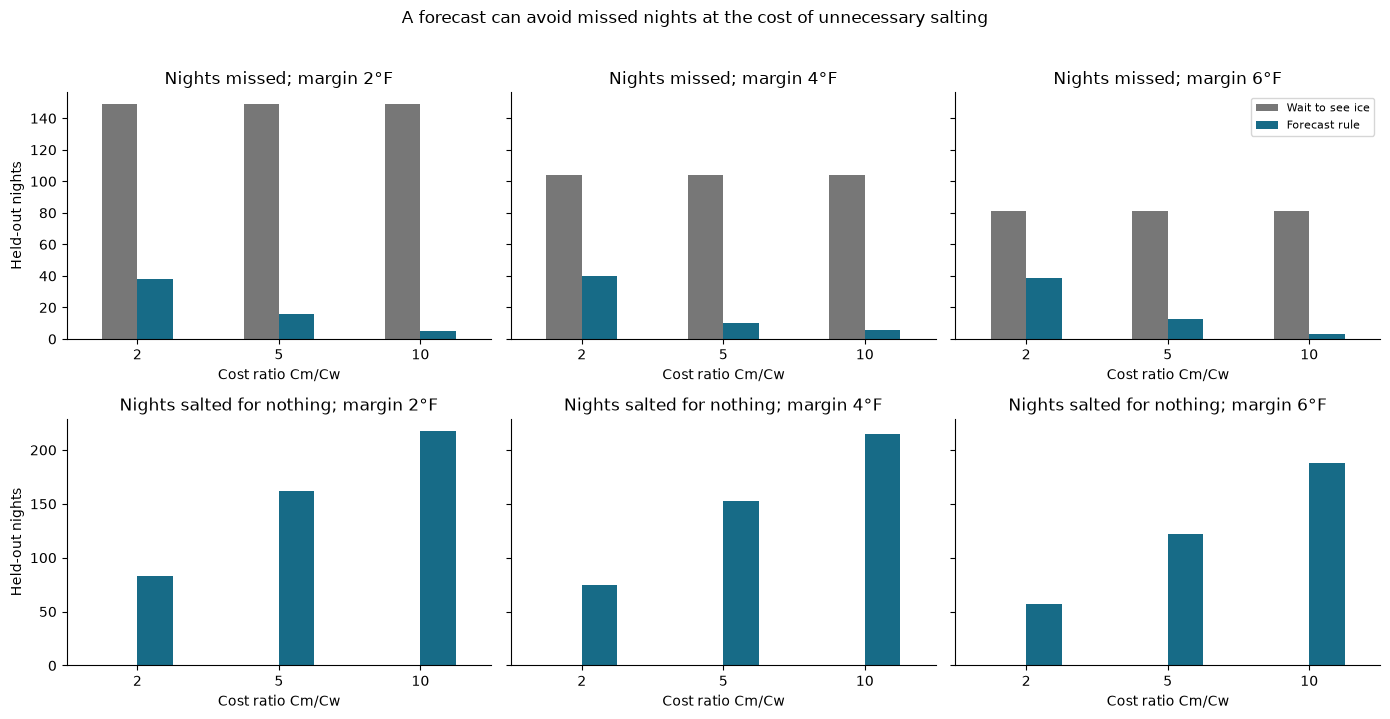

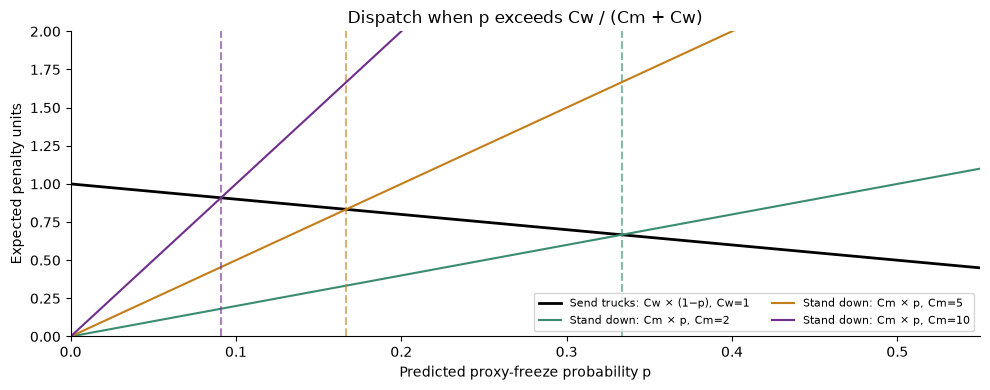

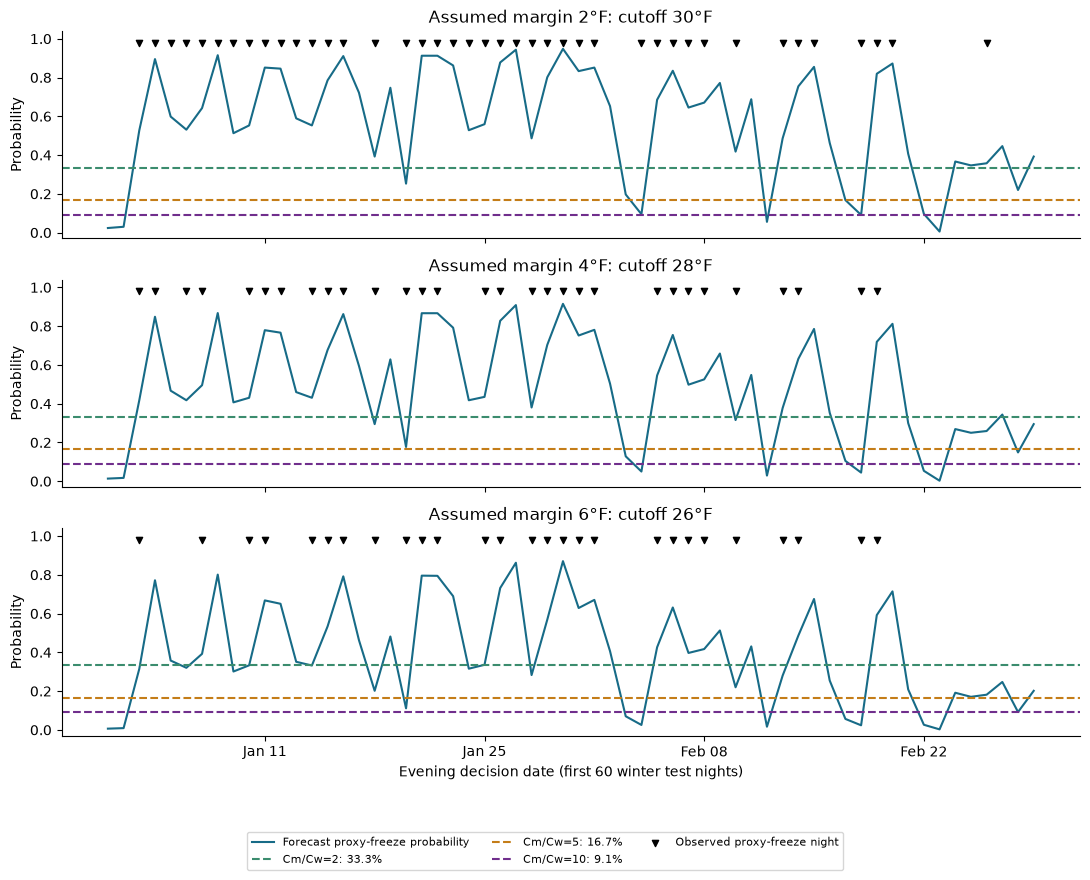

In [4]:
decision_rows=[]
nightly_predictions=pd.DataFrame({'decision_date':test.index,'overnight_min_F':actual})
for margin in MARGINS:
    freeze=actual<=32-margin
    for name in pred_test:
        nightly_predictions[f'{name}_p_margin_{margin}']=prob[name,margin]
    for ratio in RATIOS:
        threshold=1/(ratio+1)
        methods={'Wait to see ice':np.zeros(len(test),dtype=bool),
                 'Forecast rule':prob['Forecast rule',margin]>threshold,
                 'Persistence':prob['Persistence',margin]>threshold,
                 'Always salt':np.ones(len(test),dtype=bool)}
        for name,action in methods.items():
            missed=int((~action & freeze).sum())
            wasted=int((action & ~freeze).sum())
            total=ratio*missed+wasted
            decision_rows.append({'margin_F':margin,'Dulles_cutoff_F':32-margin,'Cm_over_Cw':ratio,'method':name,
                'probability_threshold':threshold,'test_nights':len(test),'proxy_freeze_nights':int(freeze.sum()),
                'salted_nights':int(action.sum()),'missed_nights':missed,'salted_for_nothing_nights':wasted,
                'total_penalty_units':total,'penalty_per_100_nights':100*total/len(test)})
scores=pd.DataFrame(decision_rows)
# Check baseline interpretation, scoring, and monotonicity of the action across assumed costs/margins.
wait=scores[scores.method=='Wait to see ice']
assert (wait.missed_nights==wait.proxy_freeze_nights).all() and (wait.salted_for_nothing_nights==0).all()
assert (scores.total_penalty_units == scores.Cm_over_Cw*scores.missed_nights+scores.salted_for_nothing_nights).all()
for name in pred_test:
    assert np.all(prob[name,2] >= prob[name,4]) and np.all(prob[name,4] >= prob[name,6])
    for margin in MARGINS:
        counts=[(prob[name,margin]>1/(r+1)).sum() for r in RATIOS]
        assert counts==sorted(counts)
primary=scores[scores.method.isin(['Wait to see ice','Forecast rule'])]
display(primary[['margin_F','Dulles_cutoff_F','Cm_over_Cw','method','missed_nights','salted_for_nothing_nights','total_penalty_units']])
scores.to_csv(FIG/'decision_scores.csv',index=False)
nightly_predictions.to_csv(ROOT/'data/nightly_predictions.csv',index=False)
fig,axes=plt.subplots(1,3,figsize=(14,4),sharey=True)
for ax,margin in zip(axes,MARGINS):
    sub=scores[(scores.margin_F==margin)&scores.method.isin(['Wait to see ice','Forecast rule'])]
    sub.pivot(index='Cm_over_Cw',columns='method',values='penalty_per_100_nights')[['Wait to see ice','Forecast rule']].plot.bar(ax=ax,rot=0,color=['#777777','#176b87'])
    ax.set(title=f'Assumed margin {margin}°F: cutoff {32-margin}°F',xlabel='Missed-night cost / wasted-salt cost')
    ax.get_legend().remove()
axes[0].set_ylabel('Penalty units per 100 held-out nights')
axes[-1].legend(fontsize=8)
fig.suptitle('Afternoon forecast vs waiting for ice — same 18:00–08:00 held-out nights',y=1.03)
save('decision_loss.png')
# Show the two actual scoring components for every scenario, without hiding them in a weighted total.
fig,axes=plt.subplots(2,3,figsize=(14,7),sharey='row')
for j,margin in enumerate(MARGINS):
    for i,(col,title) in enumerate([('missed_nights','Nights missed'),('salted_for_nothing_nights','Nights salted for nothing')]):
        sub=primary[primary.margin_F==margin]
        sub.pivot(index='Cm_over_Cw',columns='method',values=col)[['Wait to see ice','Forecast rule']].plot.bar(ax=axes[i,j],rot=0,color=['#777777','#176b87'])
        axes[i,j].set(title=f'{title}; margin {margin}°F',xlabel='Cost ratio Cm/Cw')
        axes[i,j].get_legend().remove()
axes[0,0].set_ylabel('Held-out nights'); axes[1,0].set_ylabel('Held-out nights')
axes[0,-1].legend(fontsize=8)
fig.suptitle('A forecast can avoid missed nights at the cost of unnecessary salting',y=1.02)
save('missed_and_wasted_nights.png')
# Thresholds are determined by costs, independently of the temperature-margin assumption.
p_grid=np.linspace(0,1,1001)
fig,ax=plt.subplots(figsize=(10,4))
ax.plot(p_grid,1-p_grid,color='black',lw=2,label='Send trucks: Cw × (1−p), Cw=1')
for ratio,color in zip(RATIOS,['#3b8c6e','#c47d18','#702e8c']):
    ax.plot(p_grid,ratio*p_grid,color=color,label=f'Stand down: Cm × p, Cm={ratio}')
    ax.axvline(1/(ratio+1),ls='--',color=color,alpha=.6)
ax.set(xlim=(0,.55),ylim=(0,2),xlabel='Predicted proxy-freeze probability p',ylabel='Expected penalty units',title='Dispatch when p exceeds Cw / (Cm + Cw)')
ax.legend(fontsize=8,ncol=2)
save('cost_thresholds.png')
# Chronological example: first 60 test-season decision nights (not chosen for the largest improvement).
winter=test.index[(test.index.month>=11)|(test.index.month<=3)][:60]
fig,axes=plt.subplots(3,1,figsize=(11,8),sharex=True)
mask=test.index.isin(winter)
for ax,margin in zip(axes,MARGINS):
    ax.plot(test.index[mask],prob['Forecast rule',margin][mask],label='Forecast proxy-freeze probability',color='#176b87')
    for ratio,color in zip(RATIOS,['#3b8c6e','#c47d18','#702e8c']):
        ax.axhline(1/(ratio+1),ls='--',color=color,label=f'Cm/Cw={ratio}: {1/(ratio+1):.1%}')
    events=(actual<=32-margin)&mask
    ax.scatter(test.index[events],np.full(events.sum(),.98),marker='v',color='black',s=20,label='Observed proxy-freeze night')
    ax.set(ylim=(-.03,1.04),ylabel='Probability',title=f'Assumed margin {margin}°F: cutoff {32-margin}°F')
axes[-1].xaxis.set_major_locator(mdates.WeekdayLocator(interval=2))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
axes[-1].set_xlabel('Evening decision date (first 60 winter test nights)')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(.5,-.04), ncol=3, fontsize=8)
save('nightly_probability.png')


## Calibration, residuals, and uncertainty
Check proxy-freeze probability calibration separately for **each margin**, using the same test nights and five fixed probability bins. Airport/proxy reliability is not evidence of campus-pavement calibration. Inspect temporal and seasonal temperature errors without retuning the model. These forecasts have one fixed overnight horizon; no longer-horizon performance is established.


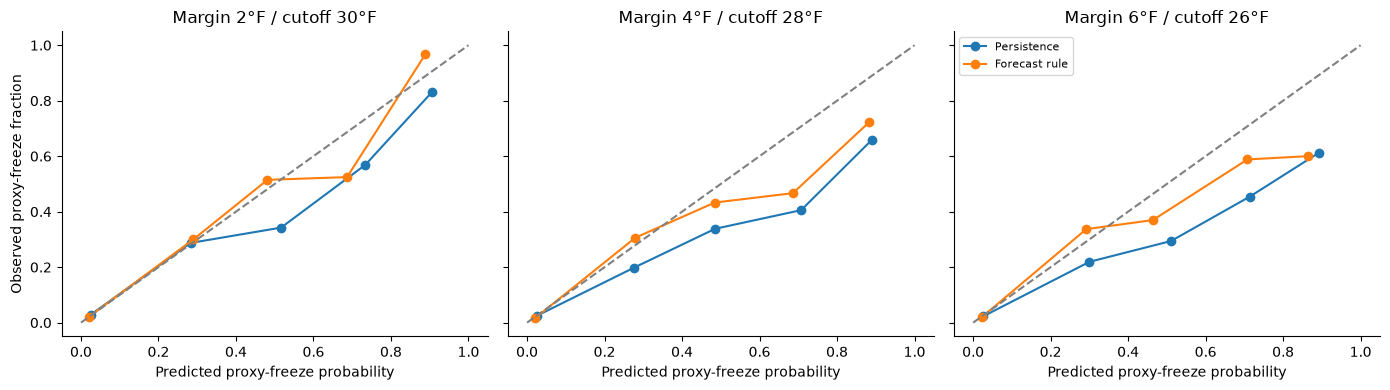

,bin,mean_probability,observed_fraction,nights,method,margin_F
0,"(-0.001, 0.2]",0.026,0.029,822,Persistence,2
1,"(0.2, 0.4]",0.283,0.287,94,Persistence,2
2,"(0.4, 0.6]",0.516,0.342,73,Persistence,2
3,"(0.6, 0.8]",0.734,0.569,51,Persistence,2
4,"(0.8, 1.0]",0.905,0.830,53,Persistence,2
5,"(-0.001, 0.2]",0.020,0.021,814,Forecast rule,2
6,"(0.2, 0.4]",0.290,0.300,120,Forecast rule,2
7,"(0.4, 0.6]",0.481,0.515,68,Forecast rule,2
8,"(0.6, 0.8]",0.687,0.525,61,Forecast rule,2
9,"(0.8, 1.0]",0.888,0.967,30,Forecast rule,2


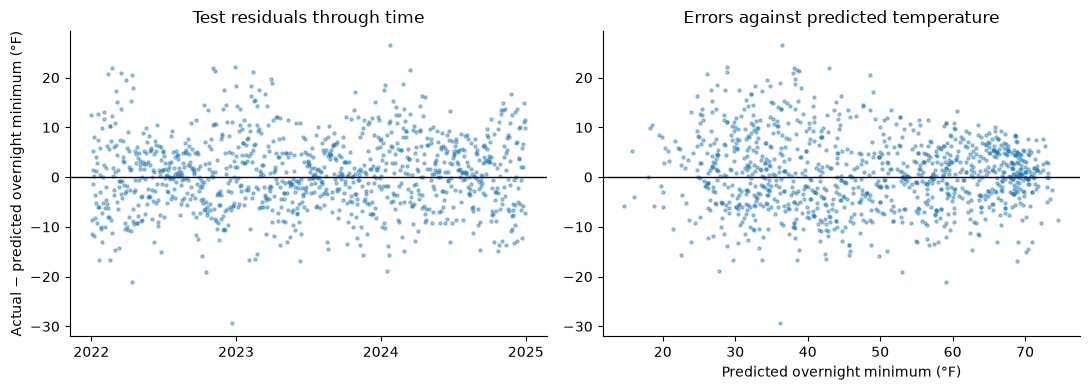

,nights,coverage,mean_error_F
season,,,
Apr–Oct,639,0.9358,0.2733
Nov–Mar,454,0.8040,1.3520


,nights,mean_error_F,MAE_F
year,,,
2022,365,0.062,5.809
2023,365,0.820,5.409
2024,363,1.285,6.014


Lag-1 test residual correlation (calendar gaps preserved): -0.04


method               Forecast rule  Wait to see ice  saving_vs_waiting
margin_F Cm_over_Cw                                                   
2        2                     159              298                139
         5                     242              745                503
         10                    268             1490               1222
4        2                     155              208                 53
         5                     203              520                317
         10                    275             1040                765
6        2                     135              162                 27
         5                     187              405                218
         10                    218              810                592

**Computed findings:** forecast MAE is 5.74°F versus persistence 6.46°F. Nominal 90% interval coverage is 88.1% overall and 80.4% in November–March. Residual lag-1 correlation is -0.040; inspect the plots before treating errors as noise. The nine margin/cost comparisons above reveal where the forecast improves on waiting and where it does not; no scenario is selected because it looks best. A perfect forecast has zero regret in this simplified loss, so current penalty is only an upper bound on the value of perfect information, not guaranteed savings.

In [5]:
residual=actual-pred_test['Forecast rule']
fig,axes=plt.subplots(1,3,figsize=(14,4),sharex=True,sharey=True)
calibration_rows=[]
for ax,margin in zip(axes,MARGINS):
    outcome=actual<=32-margin
    for name in pred_test:
        p=prob[name,margin]
        group=pd.DataFrame({'bin':pd.cut(p,np.linspace(0,1,6),include_lowest=True),'p':p,'event':outcome}).groupby('bin',observed=True)
        table=group.agg(mean_probability=('p','mean'),observed_fraction=('event','mean'),nights=('event','size'))
        ax.plot(table.mean_probability,table.observed_fraction,'o-',label=name)
        table['method'],table['margin_F']=name,margin
        calibration_rows.append(table.reset_index())
    ax.plot([0,1],[0,1],'--',color='gray')
    ax.set(title=f'Margin {margin}°F / cutoff {32-margin}°F',xlabel='Predicted proxy-freeze probability')
axes[0].set_ylabel('Observed proxy-freeze fraction')
axes[-1].legend(fontsize=8)
save('residuals_calibration.png')
calibration_table=pd.concat(calibration_rows,ignore_index=True)
display(calibration_table.round(3))
calibration_table.to_csv(FIG/'calibration_scores.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].scatter(test.index,residual,s=5,alpha=.4)
axes[0].axhline(0,color='black',lw=1)
axes[0].xaxis.set_major_locator(mdates.YearLocator())
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[0].set(title='Test residuals through time',ylabel='Actual − predicted overnight minimum (°F)')
axes[1].scatter(pred_test['Forecast rule'],residual,s=5,alpha=.4)
axes[1].axhline(0,color='black',lw=1)
axes[1].set(xlabel='Predicted overnight minimum (°F)',title='Errors against predicted temperature')
save('temperature_residuals.png')
lo,hi=intervals['Forecast rule']
seasonal=pd.DataFrame({'season':np.where(test.index.month.isin([11,12,1,2,3]),'Nov–Mar','Apr–Oct'),
    'covered':(actual>=lo)&(actual<=hi),'residual_F':residual}).groupby('season').agg(nights=('covered','size'),coverage=('covered','mean'),mean_error_F=('residual_F','mean'))
display(seasonal.round(4))
yearly=pd.DataFrame({'year':test.index.year,'error_F':residual,'abs_error_F':abs(residual)}).groupby('year').agg(nights=('error_F','size'),mean_error_F=('error_F','mean'),MAE_F=('abs_error_F','mean'))
display(yearly.round(3))
autocorr=pd.Series(residual,index=test.index).reindex(df.index).autocorr()
print('Lag-1 test residual correlation (calendar gaps preserved):',round(autocorr,3))
comparison=primary.pivot(index=['margin_F','Cm_over_Cw'],columns='method',values='total_penalty_units')
comparison['saving_vs_waiting']=comparison['Wait to see ice']-comparison['Forecast rule']
display(comparison)
summary={'test_nights':len(test),'complete_nights':int(night.tmin_f.notna().sum()),'candidate_nights':len(night),
    'train_nights':len(train),'calibration_nights':len(cal),'excluded_model_rows':len(df)-len(usable),
    'forecast_MAE_F':float(forecast_scores.loc[1,'MAE_F']),'persistence_MAE_F':float(forecast_scores.loc[0,'MAE_F']),
    'interval_coverage':float(forecast_scores.loc[1,'90pct_interval_coverage']),
    'cold_season_coverage':float(seasonal.loc['Nov–Mar','coverage']),'residual_lag1':float(autocorr)}
(FIG/'result_summary.json').write_text(json.dumps(summary,indent=2)+'\n')
display(Markdown(f"**Computed findings:** forecast MAE is {summary['forecast_MAE_F']:.2f}°F versus persistence {summary['persistence_MAE_F']:.2f}°F. Nominal 90% interval coverage is {summary['interval_coverage']:.1%} overall and {summary['cold_season_coverage']:.1%} in November–March. Residual lag-1 correlation is {autocorr:.3f}; inspect the plots before treating errors as noise. The nine margin/cost comparisons above reveal where the forecast improves on waiting and where it does not; no scenario is selected because it looks best. A perfect forecast has zero regret in this simplified loss, so current penalty is only an upper bound on the value of perfect information, not guaranteed savings."))


## Simulation check
Generate regression responses with known coefficients on the training design and recover them by refitting, seed 600. This checks the fitting implementation; it does not validate Gaussian, independent weather errors. Compare the simulated residual shape with the real training errors.


,parameter,generating,recovered
0,intercept,8.0,7.926
1,lag1,0.6,0.602
2,lag2,0.2,0.197
3,sin_year,3.0,3.057
4,cos_year,-4.0,-4.089


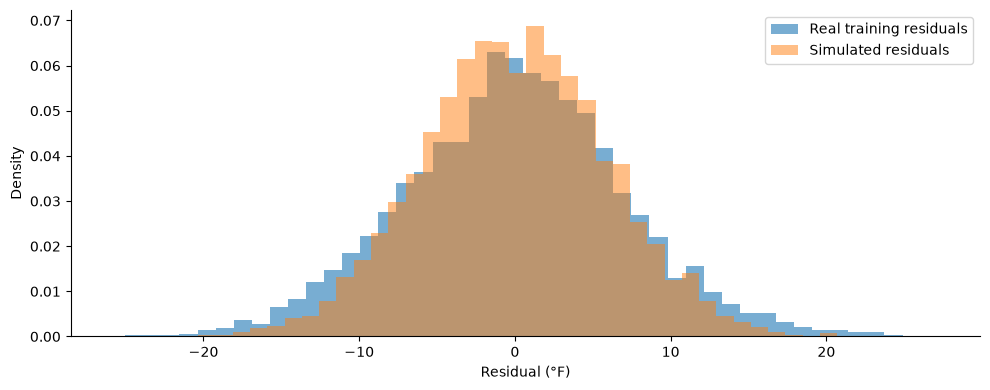

In [6]:
X=train[features].to_numpy()
beta=np.array([8.,.6,.2,3.,-4.])
sim_y=beta[0]+X@beta[1:]+rng.normal(0,6,len(train))
sim_fit=LinearRegression().fit(X,sim_y)
display(pd.DataFrame({'parameter':['intercept']+features,'generating':beta,'recovered':[sim_fit.intercept_,*sim_fit.coef_]}).round(3))
plt.hist(train.tmin_f-model.predict(train[features]),bins=45,density=True,alpha=.6,label='Real training residuals')
plt.hist(sim_y-sim_fit.predict(X),bins=45,density=True,alpha=.5,label='Simulated residuals')
plt.xlabel('Residual (°F)'); plt.ylabel('Density'); plt.legend()
save('simulation_check.png')


## Layers and limitations
The overnight temperature model produces a distribution. **The assumed margin** maps airport temperature to a proxy-freeze probability. **The two costs** determine the dispatch threshold. These are separate assumptions: costs do not change weather probability, and a temperature margin does not determine error costs.

The professor's below-32 mapping is implemented explicitly, not empirically validated. A different physical relation could reverse or change that offset; obtain paired pavement/airport temperatures and wetness observations before treating these probabilities as actual lot-freeze probabilities. Unknown true margin and costs make sensitivity reporting more defensible than picking the best-looking test scenario.

ISD-Lite rounds observations and removes quality flags; an hourly-sampled minimum can miss the true minimum between samples. Complete-night filtering can select easier conditions. Archive data may have corrections or reporting delays, so this is retrospective, not a verified real-time system. Neither actual ice formation nor GMU's reactive behavior was observed. Wetness, salt effectiveness, pavement state and actual dollars remain unmeasured. There is no claim of injury prevention, actual savings, or performance at another location or horizon.

The old daily-target test was inspected before this correction. The revision follows instructor-defined changes; it is not a fresh model-selection opportunity. Before the final presentation, team members must choose or retain explicit scenario assumptions, check those assumptions with local evidence, and audit real-time predictor availability.


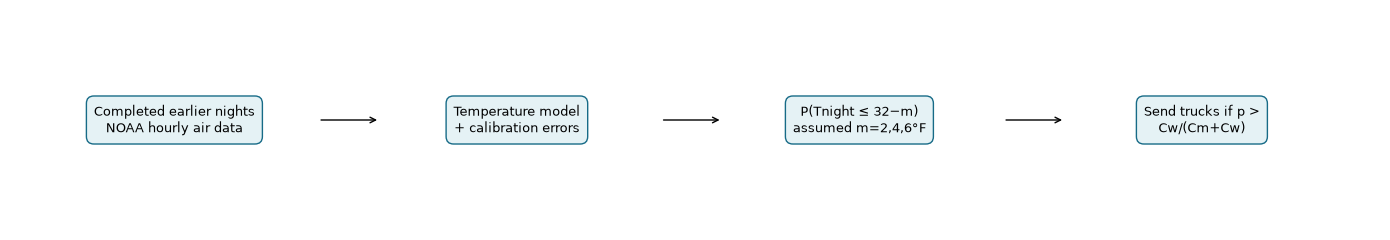

In [7]:
fig,ax=plt.subplots(figsize=(14,2.5))
ax.axis('off')
labels=['Completed earlier nights\nNOAA hourly air data','Temperature model\n+ calibration errors','P(Tnight ≤ 32−m)\nassumed m=2,4,6°F','Send trucks if p >\nCw/(Cm+Cw)']
for i,label in enumerate(labels):
    x=.12+i*.25
    ax.text(x,.5,label,ha='center',va='center',fontsize=9,bbox={'boxstyle':'round,pad=.6','facecolor':'#e5f2f5','edgecolor':'#176b87'},transform=ax.transAxes)
    if i<3:
        ax.annotate('',xy=(x+.15,.5),xytext=(x+.105,.5),xycoords='axes fraction',arrowprops={'arrowstyle':'->'})
save('layers.png')
